In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from main import SimulationType

dataset_name = "Brouwer_2019"
simulation_type = "BASELINE"

df = pd.read_parquet(
    "screening_results",
    #filters=[
    #    ("dataset_name", "=", dataset_name),
             #("simulation_type", "=", simulation_type),
    #         ]
)
print(df.shape[0])
df


26379


,index,doi,title,abstract,incl,link,publication_year,sim_seen,sim_seen_in_update,random_sample,p_score,batch_number,id,review_update,texts,sim_order,prediction,run_id,dataset_name,simulation_type
0,5646,https://doi.org/10.1109/87.865852,Communication protocols for a fault-tolerant a...,We present the design and verification of inte...,0,https://api.openalex.org/W2114404022,2000.0,0,NaN,0,NaN,None,5646,0,Communication protocols for a fault-tolerant a...,0.0,0.002134,1,Hall_2012,BASELINE
1,5613,https://doi.org/10.1109/12.859537,An efficient and scalable approach for impleme...,Distributed Shared Memory (DSM) architectures ...,0,https://api.openalex.org/W2124458074,2000.0,1,NaN,1,NaN,None,5613,0,An efficient and scalable approach for impleme...,216.0,NaN,1,Hall_2012,BASELINE
2,6789,https://doi.org/10.1109/74.842123,Azimuth-track level compensation to reduce bli...,The 34-meter antennas of the NASA Deep Space N...,0,https://api.openalex.org/W2154240544,2000.0,0,NaN,0,NaN,None,6789,0,Azimuth-track level compensation to reduce bli...,0.0,0.002503,1,Hall_2012,BASELINE
3,6830,https://doi.org/10.1109/41.873223,Experimental fault-tolerant control of a PMSM ...,The paper describes a study and an experimenta...,0,https://api.openalex.org/W2164804984,2000.0,1,NaN,1,NaN,None,6830,0,Experimental fault-tolerant control of a PMSM ...,245.0,NaN,1,Hall_2012,BASELINE
4,3914,https://doi.org/10.1109/71.841738,Software-based rerouting for fault-tolerant pi...,This paper presents a software-based approach ...,0,https://api.openalex.org/W2148121445,2000.0,1,NaN,0,NaN,None,3914,0,Software-based rerouting for fault-tolerant pi...,1267.0,0.005900,1,Hall_2012,BASELINE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26374,8781,https://doi.org/10.1109/icise.2010.5689756,Fault tolerant mechanism in grid based on Back...,Grid is a very efficient technology to perform...,0,https://api.openalex.org/W2538828507,2010.0,0,NaN,0,NaN,None,8781,2,Fault tolerant mechanism in grid based on Back...,NaN,0.002121,1,Hall_2012,REORDERING
26375,1,https://doi.org/10.1109/induscon.2010.5740045,Design and development of a software for fault...,This paper presents an on-line fault diagnosis...,0,https://api.openalex.org/W2557025555,2010.0,0,NaN,0,NaN,None,1,2,Design and development of a software for fault...,NaN,0.008956,1,Hall_2012,REORDERING
26376,0,https://doi.org/10.1109/indcon.2010.5712716,Computer vision based offset error computation...,The use of computer vision based approach has ...,0,https://api.openalex.org/W2131536587,2010.0,0,NaN,0,NaN,None,0,2,Computer vision based offset error computation...,NaN,0.002587,1,Hall_2012,REORDERING
26377,8786,https://doi.org/10.1109/dsd.2010.64,Multiple Bit Error Detection and Correction in...,Technology evolution provides ever increasing ...,0,https://api.openalex.org/W2172045557,2010.0,0,NaN,0,NaN,None,8786,2,Multiple Bit Error Detection and Correction in...,NaN,0.001121,1,Hall_2012,REORDERING


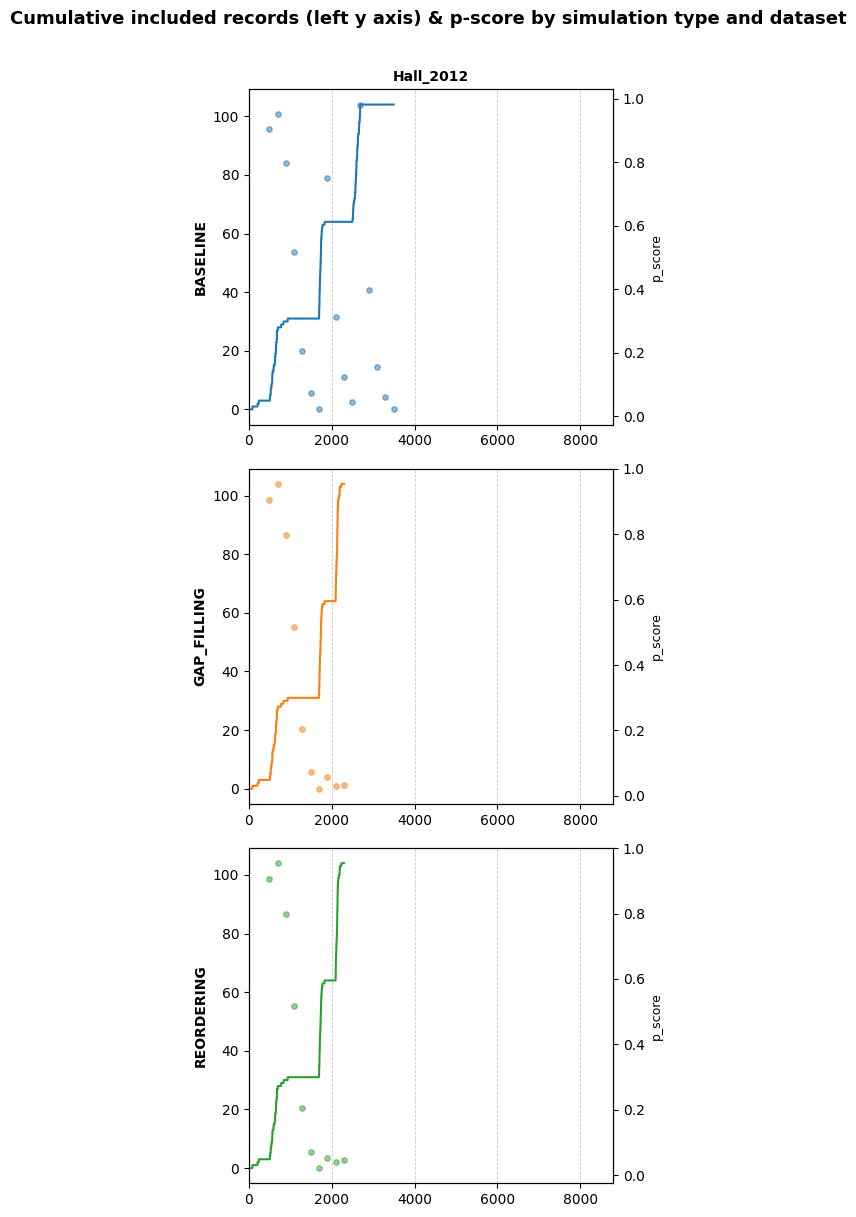

In [15]:
import numpy as np
from IPython.display import display, Latex

# Get unique values
datasets = sorted(df["dataset_name"].unique())
sim_types = sorted(df["simulation_type"].unique()) 
# sim_types = ["BASELINE"] # baseline, reordering, gap_filling

n_cols = len(datasets)
n_rows = len(sim_types)  # 3 rows

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(5 * n_cols, 4 * n_rows),
    sharex=False
)

# Ensure axes is always 2D
if n_rows == 1:
    axes = axes[np.newaxis, :]
if n_cols == 1:
    axes = axes[:, np.newaxis]

# Create twin axes grid for the right y-axis (p_score)
axes2 = np.empty_like(axes, dtype=object)
for r in range(n_rows):
    for c in range(n_cols):
        axes2[r, c] = axes[r, c].twinx()

# Color per simulation type (consistent across all subplots)
sim_color = {sim: f"C{i}" for i, sim in enumerate(sim_types)}

for c, dataset in enumerate(datasets):
    dgroup = df[df["dataset_name"] == dataset]

    for r, sim_type in enumerate(sim_types):
        ax  = axes[r, c]
        ax2 = axes2[r, c]

        sgroup = dgroup[dgroup["simulation_type"] == sim_type]
        if sgroup.empty:
            ax.set_visible(False)
            ax2.set_visible(False)
            continue

        sgroup = sgroup.sort_values("sim_order").reset_index(drop=True)
        color = sim_color[sim_type]

        ax.plot(sgroup["sim_order"], sgroup["incl"].cumsum(),
                color=color, label=sim_type)
        ax2.scatter(sgroup["sim_order"], sgroup["p_score"],
                    color=color, alpha=0.5, s=15)

        ax.set_xlim(0, sgroup.shape[0])

        # Add vertical grid lines
        ax.xaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.7, zorder=0)
        ax.set_axisbelow(True)

        # Row labels (simulation type) on the leftmost column only
        if c == 0:
            ax.set_ylabel(sim_type, fontsize=10, fontweight="bold")

        # Column labels (dataset name) on the top row only
        if r == 0:
            ax.set_title(dataset, fontsize=10, fontweight="bold")

        # Right y-axis label only on the rightmost column
        if c == n_cols - 1:
            ax2.set_ylabel("p_score", fontsize=9)
        else:
            ax2.set_yticklabels([])
        #display(Latex(f"$p={min(y):.2f}$ for $H_0$ that recall of {t['tau_target']} has not been achieved"))


#        ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Cumulative included records (left y axis) & p-score by simulation type and dataset",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
for dataset, dgroup in df.groupby("dataset_name"):
    fig, ax = plt.subplots()
    ax2 = ax.twinx()
    for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):
        sgroup = sgroup.sort_values("sim_order").reset_index(drop=True)
        #ax.set_title(str(sim_type))
        ax.plot(sgroup["sim_order"], sgroup["incl"].cumsum(), color=f"C{i}", label=sim_type)
        ax2.scatter(sgroup["sim_order"], sgroup["p_score"], color=f"C{i}", alpha=0.5)
        ax.set_xlim(xmax=sgroup.shape[0])

    ax.legend()
    plt.show()


/tmp/ipykernel_84059/3792190978.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for dataset, dgroup in df.groupby("dataset_name"):
/tmp/ipykernel_84059/3792190978.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):


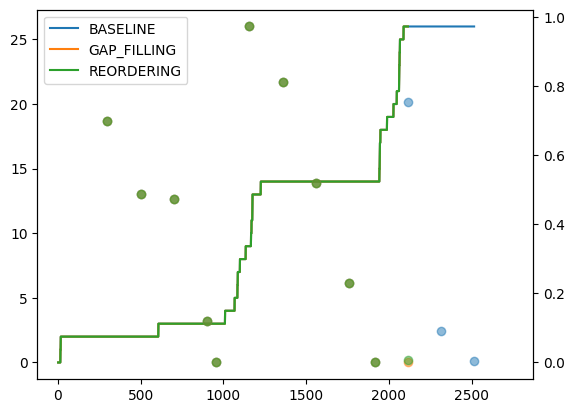

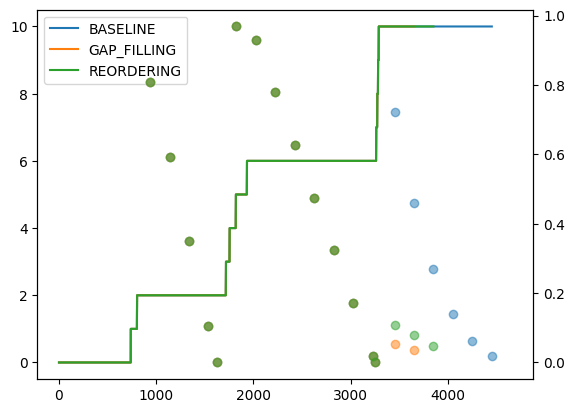

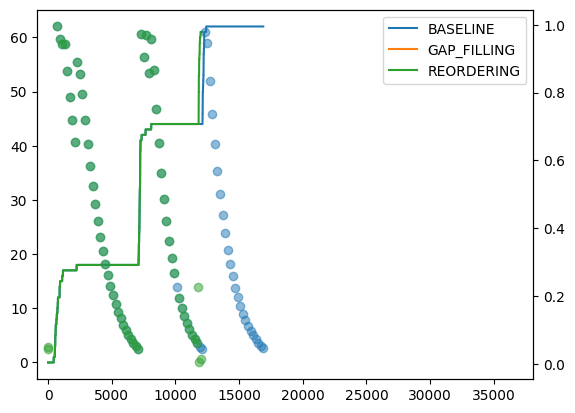

In [25]:
for dataset, dgroup in df.groupby("dataset_name"):
    fig, ax = plt.subplots()
    ax2 = ax.twinx()
    for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):
        sgroup = sgroup.sort_values("sim_order").reset_index(drop=True)
        #ax.set_title(str(sim_type))
        ax.plot(sgroup["sim_order"], sgroup["incl"].cumsum(), color=f"C{i}", label=sim_type)
        ax2.scatter(sgroup["sim_order"], sgroup["p_score"], color=f"C{i}", alpha=0.5)
        ax.set_xlim(xmax=sgroup.shape[0])

    ax.legend()
    plt.show()



/tmp/ipykernel_84059/3874760425.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for dataset, dgroup in df.groupby("dataset_name"):
/tmp/ipykernel_84059/3874760425.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):
/tmp/ipykernel_84059/3874760425.py:10: RuntimeWarning: invalid value encountered in scalar divide
  savings = 1 - n_seen / update_sgroup.shape[0]
/tmp/ipykernel_84059/3874760425.py:11: RuntimeWarning: invalid value encountered in scalar divide
  recall = update_sgroup[update_sgroup["sim_seen"]==1]["incl"].sum() / update_

,dataset,simulation_type,review_update,savings,recall
0,Appenzeller-Herzog_2019,BASELINE,0,0.000000,1.000000
1,Appenzeller-Herzog_2019,BASELINE,1,0.079332,1.000000
2,Appenzeller-Herzog_2019,BASELINE,2,0.179255,1.000000
3,Appenzeller-Herzog_2019,GAP_FILLING,0,0.000000,1.000000
4,Appenzeller-Herzog_2019,GAP_FILLING,1,0.000000,1.000000
5,Appenzeller-Herzog_2019,GAP_FILLING,2,0.263488,1.000000
6,Appenzeller-Herzog_2019,REORDERING,0,0.000000,1.000000
7,Appenzeller-Herzog_2019,REORDERING,1,0.000000,1.000000
8,Appenzeller-Herzog_2019,REORDERING,2,0.263488,1.000000
9,Bos_2018,BASELINE,0,0.000000,1.000000


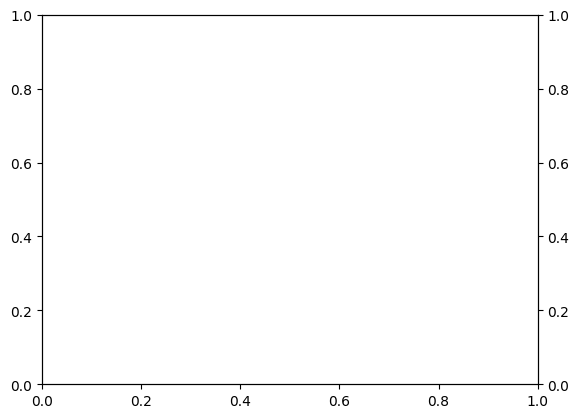

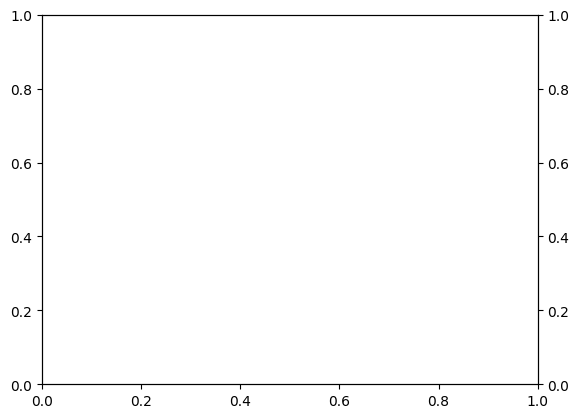

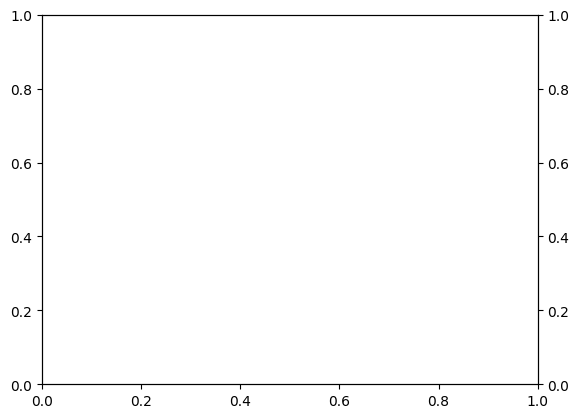

In [23]:
results_table = []
for dataset, dgroup in df.groupby("dataset_name"):
    fig, ax = plt.subplots()
    ax2 = ax.twinx()
    for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):

        for review_update in [0,1,2]:
            update_sgroup = sgroup[sgroup["review_update"]<=review_update]
            n_seen = update_sgroup["sim_seen"].sum()
            savings = 1 - n_seen / update_sgroup.shape[0]
            recall = update_sgroup[update_sgroup["sim_seen"]==1]["incl"].sum() / update_sgroup["incl"].sum()
            results_table.append({
                "dataset": dataset,
                "simulation_type": sim_type,
                "review_update": review_update,
                "savings": savings,
                "recall": recall
            })

pd.DataFrame(results_table)

In [13]:
sgroup[
    sgroup["sim_seen"]==1 
]

,index,doi,title,abstract,incl,link,publication_year,sim_seen,sim_seen_in_update,random_sample,p_score,batch_number,id,review_update,texts,sim_order,prediction,run_id,dataset_name,simulation_type
18375,3347,None,"Dementia, apathy, and thalamic infarcts",Two men in their seventies were referred for d...,0,https://api.openalex.org/W2491381414,1955.0,1,NaN,1,NaN,None,3347,0,"Dementia, apathy, and thalamic infarcts Two me...",537.0,NaN,1,Bos_2018,REORDERING
18376,3287,None,Parvalbumin neurons in the hippocampus in seni...,The immunogold-silver-staining method (IGSS) w...,0,https://api.openalex.org/W3186159688,1955.0,1,NaN,0,NaN,None,3287,0,Parvalbumin neurons in the hippocampus in seni...,1105.0,0.002378,1,Bos_2018,REORDERING
18377,1090,None,The clinical significance of white-matter-lesi...,30 patients with myotonic dystrophy (MD) were ...,0,https://api.openalex.org/W2523621469,1955.0,1,NaN,0,NaN,None,1090,0,The clinical significance of white-matter-lesi...,1252.0,0.001821,1,Bos_2018,REORDERING
18378,3721,None,Cerebral Microbleedings and Late Stroke Onset ...,Cerebral autosomal dominant arteriopathy with ...,0,https://api.openalex.org/W2613599922,1955.0,1,NaN,1,NaN,None,3721,0,Cerebral Microbleedings and Late Stroke Onset ...,408.0,NaN,1,Bos_2018,REORDERING
18379,677,None,“Behavioral imaging”―a procedure for analysis ...,We present a procedure for quantitation and to...,0,https://api.openalex.org/W2626618100,1955.0,1,NaN,1,NaN,None,677,0,“Behavioral imaging”―a procedure for analysis ...,520.0,NaN,1,Bos_2018,REORDERING
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23243,4190,https://doi.org/10.1016/j.jstrokecerebrovasdis...,Clinical Predictors of Stroke Mimics in Patien...,Multimodal computed tomography imaging (MCTI) ...,0,https://api.openalex.org/W2767295039,2018.0,1,2.0,0,NaN,None,4190,2,Clinical Predictors of Stroke Mimics in Patien...,3580.0,0.002148,1,Bos_2018,REORDERING
23244,4194,https://doi.org/10.1016/j.neurobiolaging.2017....,Brain amyloid burden and cerebrovascular disea...,Alzheimer's disease (AD) is the most common ca...,0,https://api.openalex.org/W2771384231,2018.0,1,2.0,0,NaN,None,4194,2,Brain amyloid burden and cerebrovascular disea...,3603.0,0.001936,1,Bos_2018,REORDERING
23247,1177,https://doi.org/10.1176/appi.neuropsych.17050099,Exploring the Spectrum of Subcortical Hyperint...,White matter hyperintensities (WMHs) include p...,0,https://api.openalex.org/W2766348311,2018.0,1,2.0,0,NaN,None,1177,2,Exploring the Spectrum of Subcortical Hyperint...,3412.0,0.017051,1,Bos_2018,REORDERING
23250,4460,https://doi.org/10.1136/jnnp-2017-316724,Prevalence of hippocampal enlarged perivascula...,Objectives The clinical importance of hippocam...,0,https://api.openalex.org/W2783505031,2018.0,1,2.0,0,NaN,None,4460,2,Prevalence of hippocampal enlarged perivascula...,3389.0,0.002955,1,Bos_2018,REORDERING


In [14]:
sgroup.shape

(4878, 20)

In [16]:
interim_df = pd.read_parquet(
    "interim-screening-results",
)
interim_df = interim_df[
    (interim_df["dataset_name"] == dataset) & 
    (interim_df["simulation_type"] == "REORDERING")
]

